In [6]:
import math
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
import random
from qiskit.quantum_info import Statevector
from qiskit import QuantumCircuit
from qiskit.circuit.library import StatePreparation

In [7]:
def plot_signed_amplitude(state, title):
    labels = []
    amplitudes = []
    for i, a in enumerate(state.data):
        if abs(a) > 1e-4:
            labels.append(i)
            amplitudes.append(np.real(a))

    fig, ax = plt.subplots(figsize=(25, 6))
    ax.bar(labels, amplitudes)
    ax.axhline(y=0, color="black", linewidth=1)
    ax.set(title=title, xlabel="Data (Decimal)", ylabel="Signed Amplitude")
    ax.set_xticks(labels)
    ax.tick_params(axis="x", labelrotation=90 if len(labels) > 10 else 0)
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()

In [8]:
class GroverLong:
    def __init__(self):
        pass

    def state_preparation(self, dataset):   # basis encoding
        max_element = max(dataset)
        n_data_q = max(1, math.ceil(math.log2(max_element + 1)))
        N_padded = 2 ** n_data_q

        qc = QuantumCircuit(n_data_q)

        amplitudes = np.zeros(N_padded, dtype=complex)

        for data in dataset:
            amplitudes[data] = 1

        amplitudes /= np.linalg.norm(amplitudes)

        state_prep = StatePreparation(amplitudes)

        qc.append(state_prep, range(n_data_q))
        qc.barrier()

        return qc

    def oracle(self, n_data_q, target, phi=np.pi):
        oracle = QuantumCircuit(n_data_q, name="Oracle")
        binary_target = format(target, f"0{n_data_q}b")

        # Convert target bit pattern into all 1s
        for i, bit in enumerate(binary_target):
            qubit = n_data_q - 1 - i
            if bit == "0":
                oracle.x(qubit)

        # Apply phase to the target state
        if n_data_q == 1:
            oracle.p(phi, 0)
        else:
            oracle.mcp(phi, list(range(n_data_q - 1)), n_data_q - 1)

        # Restore original bit pattern
        for i, bit in enumerate(binary_target):
            qubit = n_data_q - 1 - i
            if bit == "0":
                oracle.x(qubit)

        oracle.barrier()
        return oracle

    def diffuser(self, dataset, n_data_q, phi=np.pi):
        diffuser = QuantumCircuit(n_data_q, name="Diffuser")

        # W dagger
        prep = self.state_preparation(dataset)
        diffuser.compose(prep.inverse(), inplace=True)

        # Convert |000...0> to |111...1>
        diffuser.x(range(n_data_q))

        # Apply phase
        if n_data_q == 1:
            diffuser.p(phi, 0)
        else:
            diffuser.mcp(phi, list(range(n_data_q - 1)), n_data_q - 1)

        # Restore original state
        diffuser.x(range(n_data_q))

        # W
        diffuser.compose(prep, inplace=True)
        diffuser.barrier()

        return diffuser

    def grover_long(self, dataset, n_data_q, target):
        qc = QuantumCircuit(n_data_q, name="Grover-long")
        qc.compose(self.state_preparation(dataset), inplace=True)

        print("\n> Initial state before Grover search:")
        state = Statevector.from_instruction(qc)
        display(state.draw("latex"))
        plot_signed_amplitude(state, "Initial State")

        M = 1 # assumed only one target element in the dataset
        N = len(dataset)
        t_optimal = round(np.pi / (4 * np.arcsin(np.sqrt(M / N))) - 0.5)
        phi = 2 * np.arcsin(np.sin(np.pi / (4 * t_optimal + 2)) / np.sqrt(M / N))
        print("\n> Calculated phase angle (phi): ", phi)
        print("> Optimal no of iterations: ", t_optimal)

        oracle = self.oracle(n_data_q, target, phi)
        diffuser = self.diffuser(dataset, n_data_q, phi)

        # Repeat Grover iterations

        for i in range(t_optimal):
            print("\n> Grover iteration", i + 1)

            # Oracle
            qc.compose(oracle, inplace=True)
            state = Statevector.from_instruction(qc)
            display(state.draw("latex"))
            plot_signed_amplitude(state, f"After Oracle - Iteration {i + 1}")

            # Diffuser
            qc.compose(diffuser, inplace=True)
            state = Statevector.from_instruction(qc)
            display(state.draw("latex"))
            plot_signed_amplitude(state, f"After Diffuser - Iteration {i + 1}")

        return qc

    def run(self, dataset, target):
        max_element = max(dataset)
        n_data_q = max(1, math.ceil(math.log2(max_element + 1)))

        print("Dataset = ", dataset)
        print("Target element = ", target)
        print("Number of data qubits = ", n_data_q)

        qc = self.grover_long(dataset, n_data_q, target)

        # Final state

        print("\n> Final quantum state:")
        state = Statevector.from_instruction(qc)
        display(state.draw("latex"))
        probabilities = state.probabilities()

        # Most probable state
        result = int(np.argmax(probabilities))
        print("\n> Search completed.")
        print("Target element = ", target)
        print("Most probable measured value = ", result)
        print("Probability of target = ", probabilities[target])

        return result

In [9]:
dataset = [i for i in range(20)]
target = random.choice(dataset)

Dataset =  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Target element =  19
Number of data qubits =  5

> Initial state before Grover search:


<IPython.core.display.Latex object>

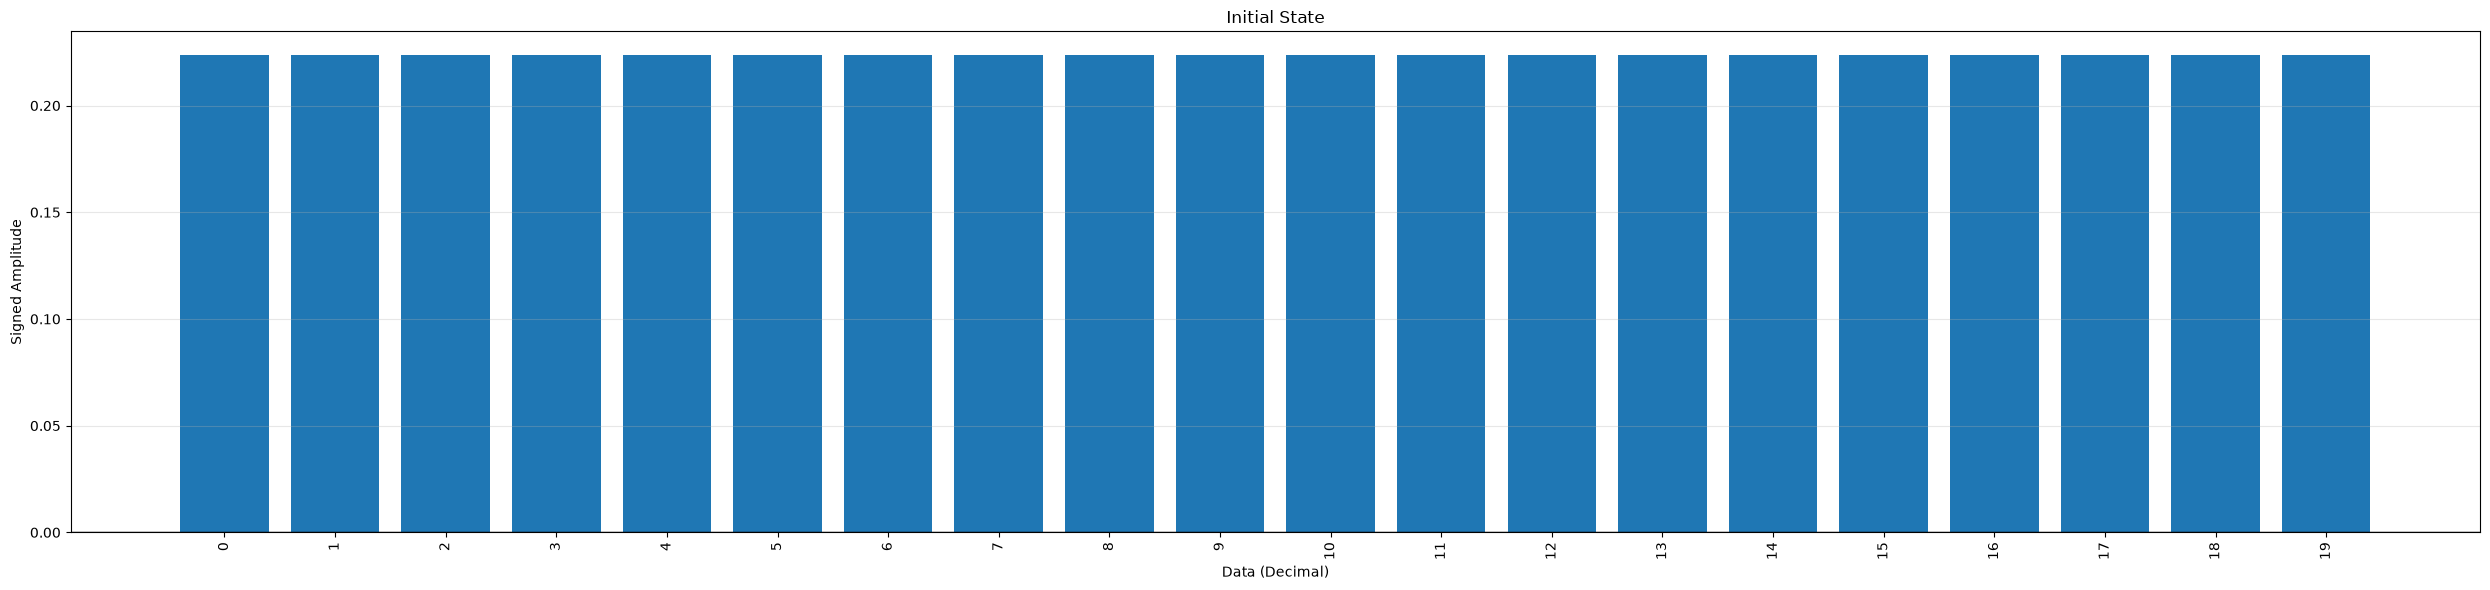


> Calculated phase angle (phi):  2.9444111951222602
> Optimal no of iterations:  3

> Grover iteration 1


<IPython.core.display.Latex object>

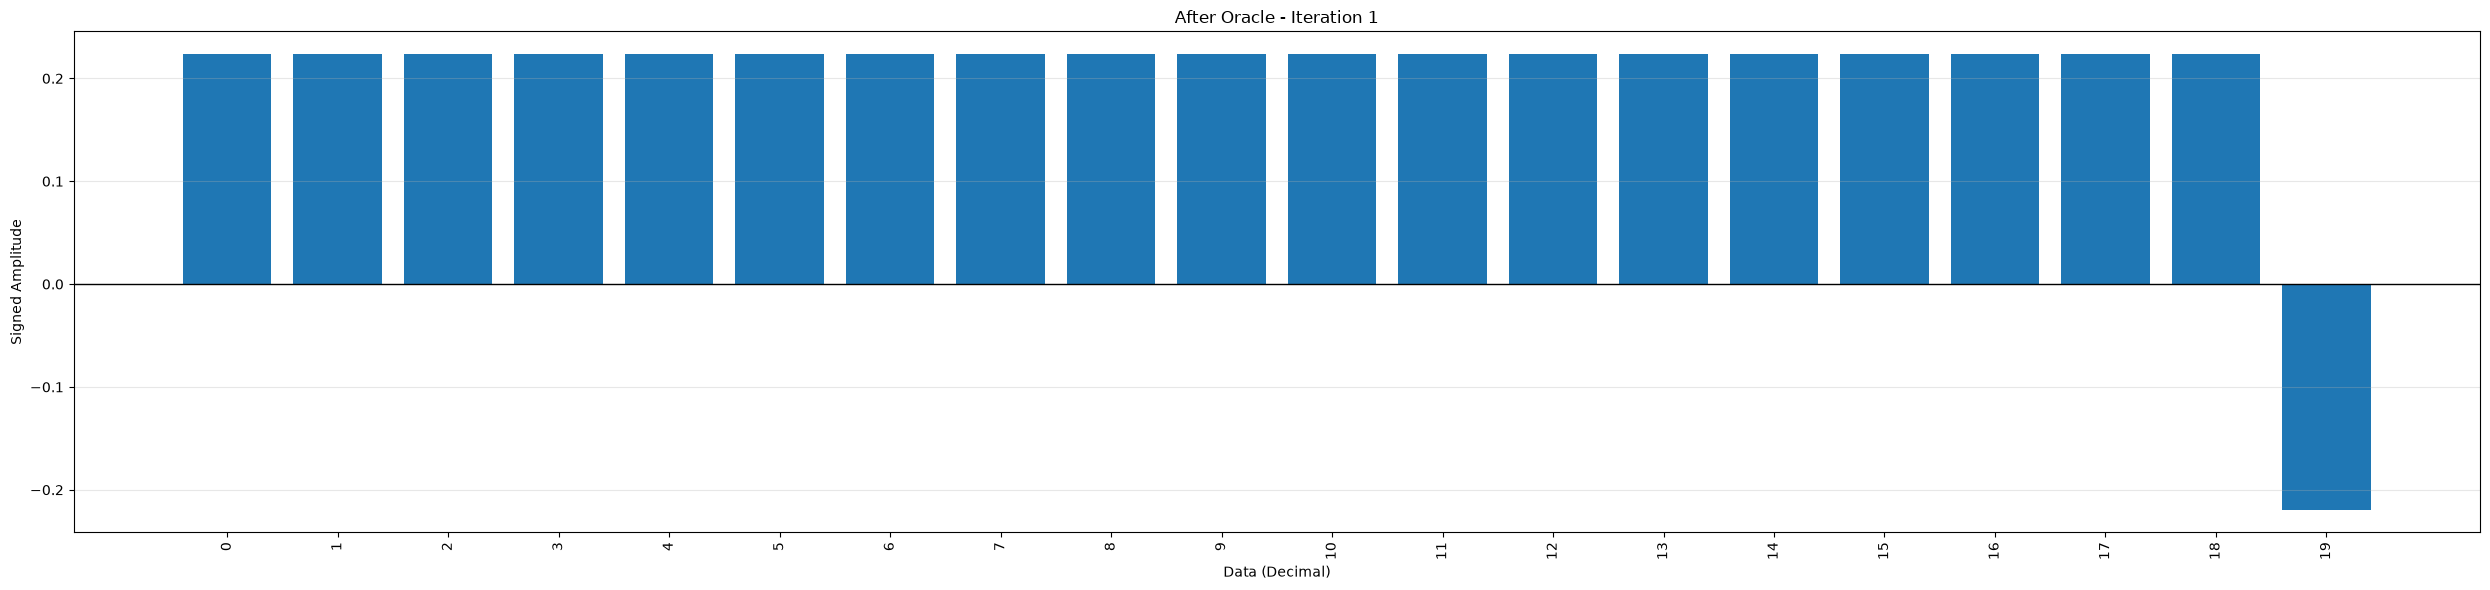

<IPython.core.display.Latex object>

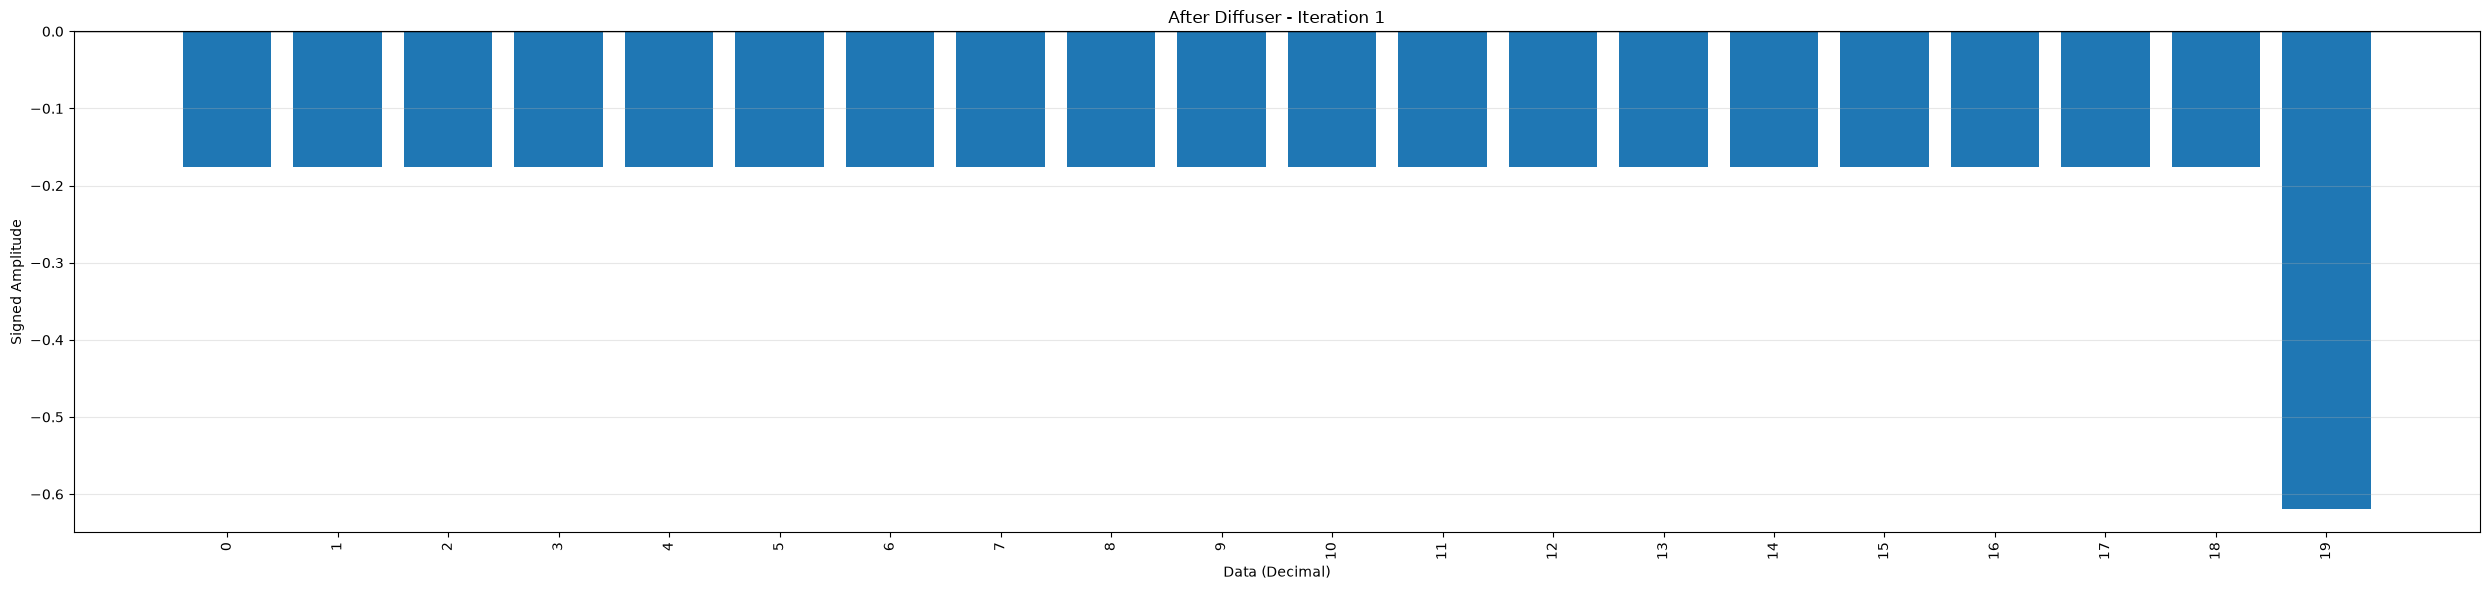


> Grover iteration 2


<IPython.core.display.Latex object>

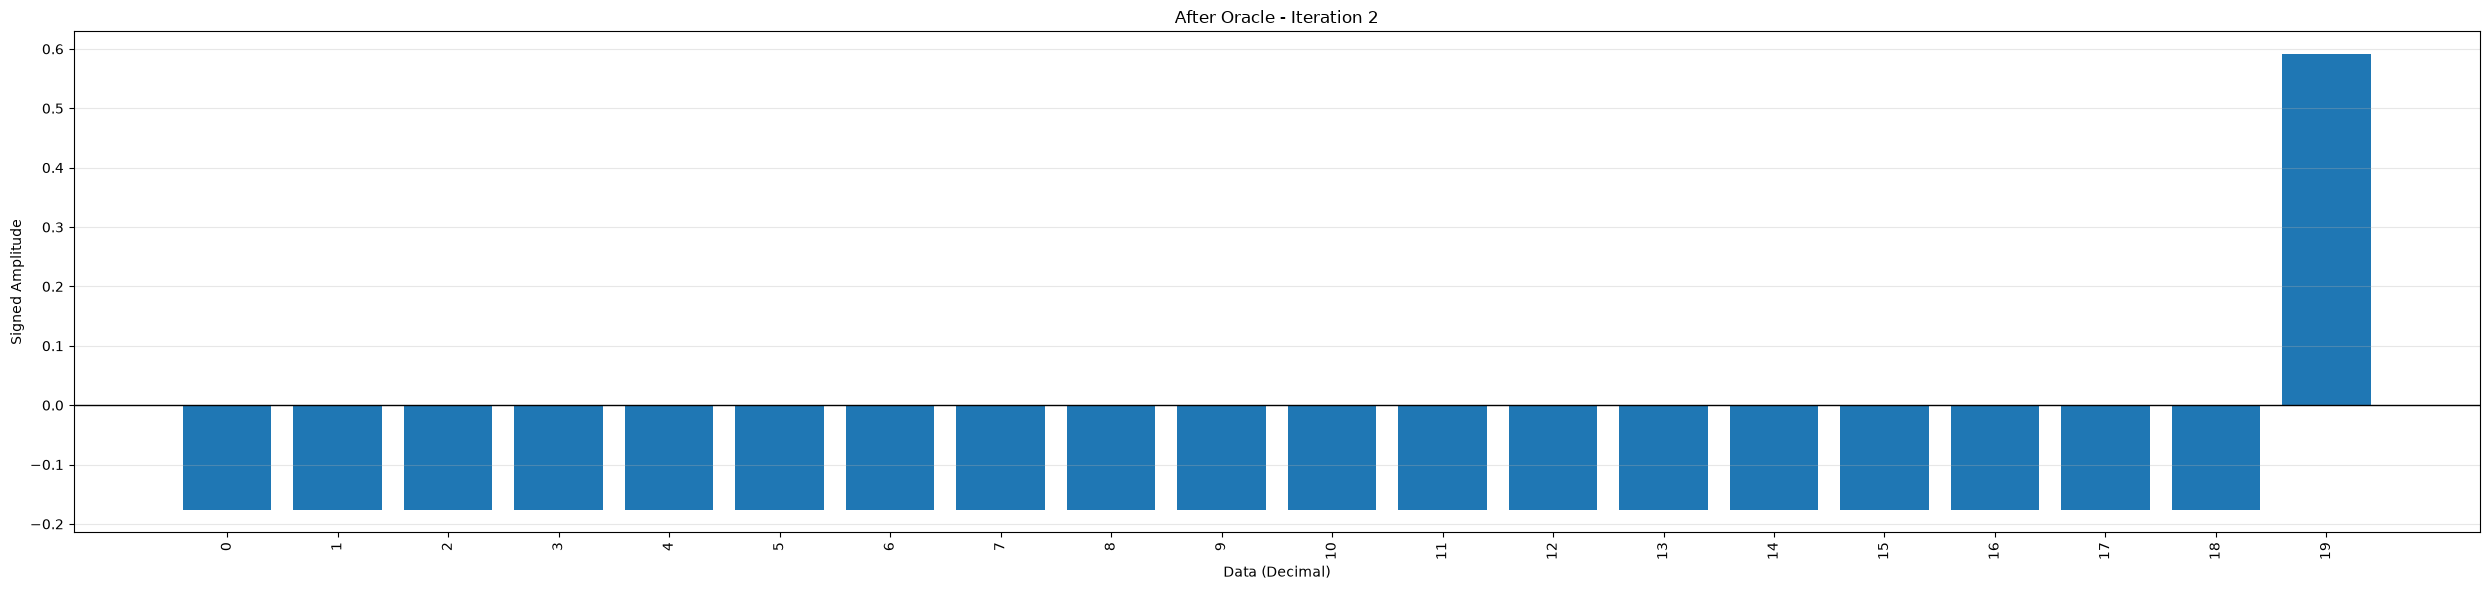

<IPython.core.display.Latex object>

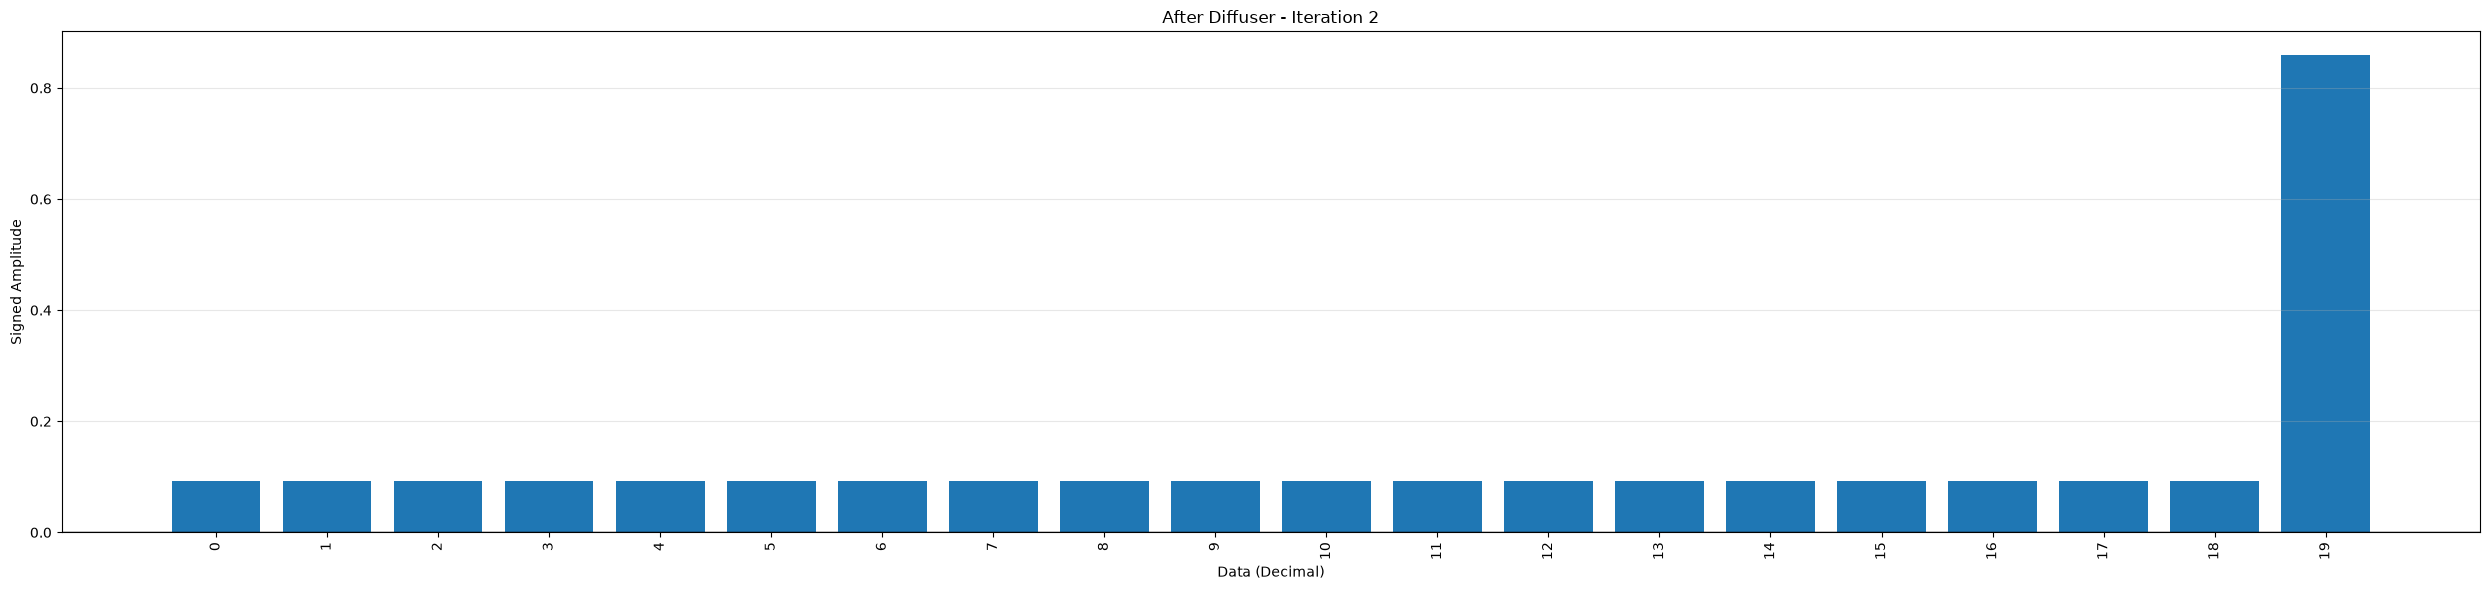


> Grover iteration 3


<IPython.core.display.Latex object>

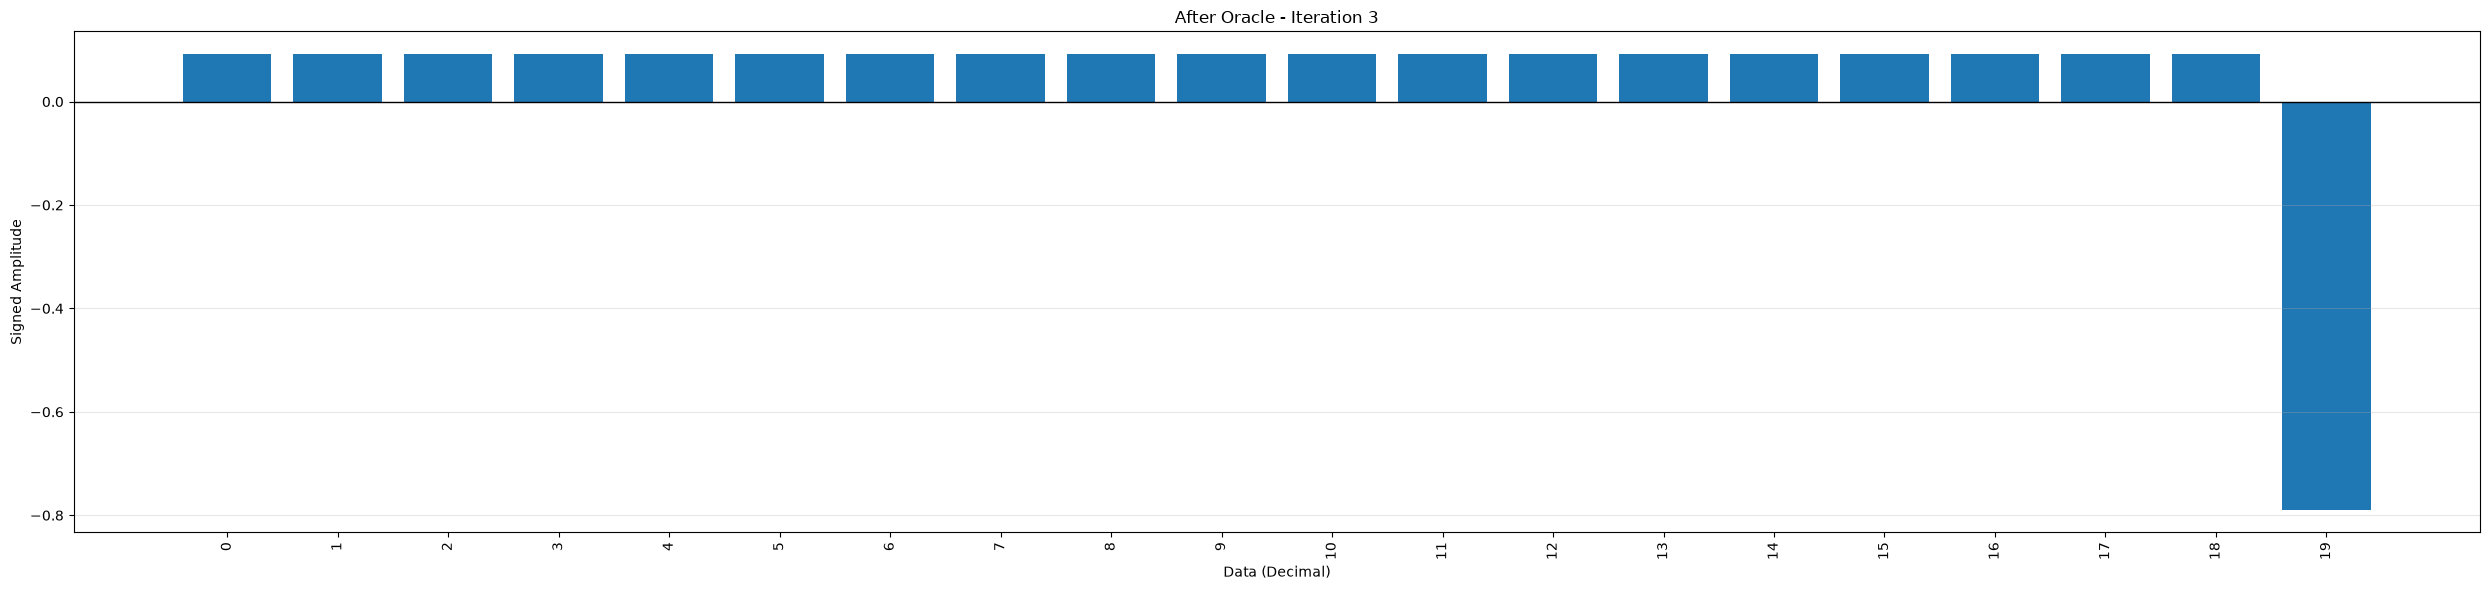

<IPython.core.display.Latex object>

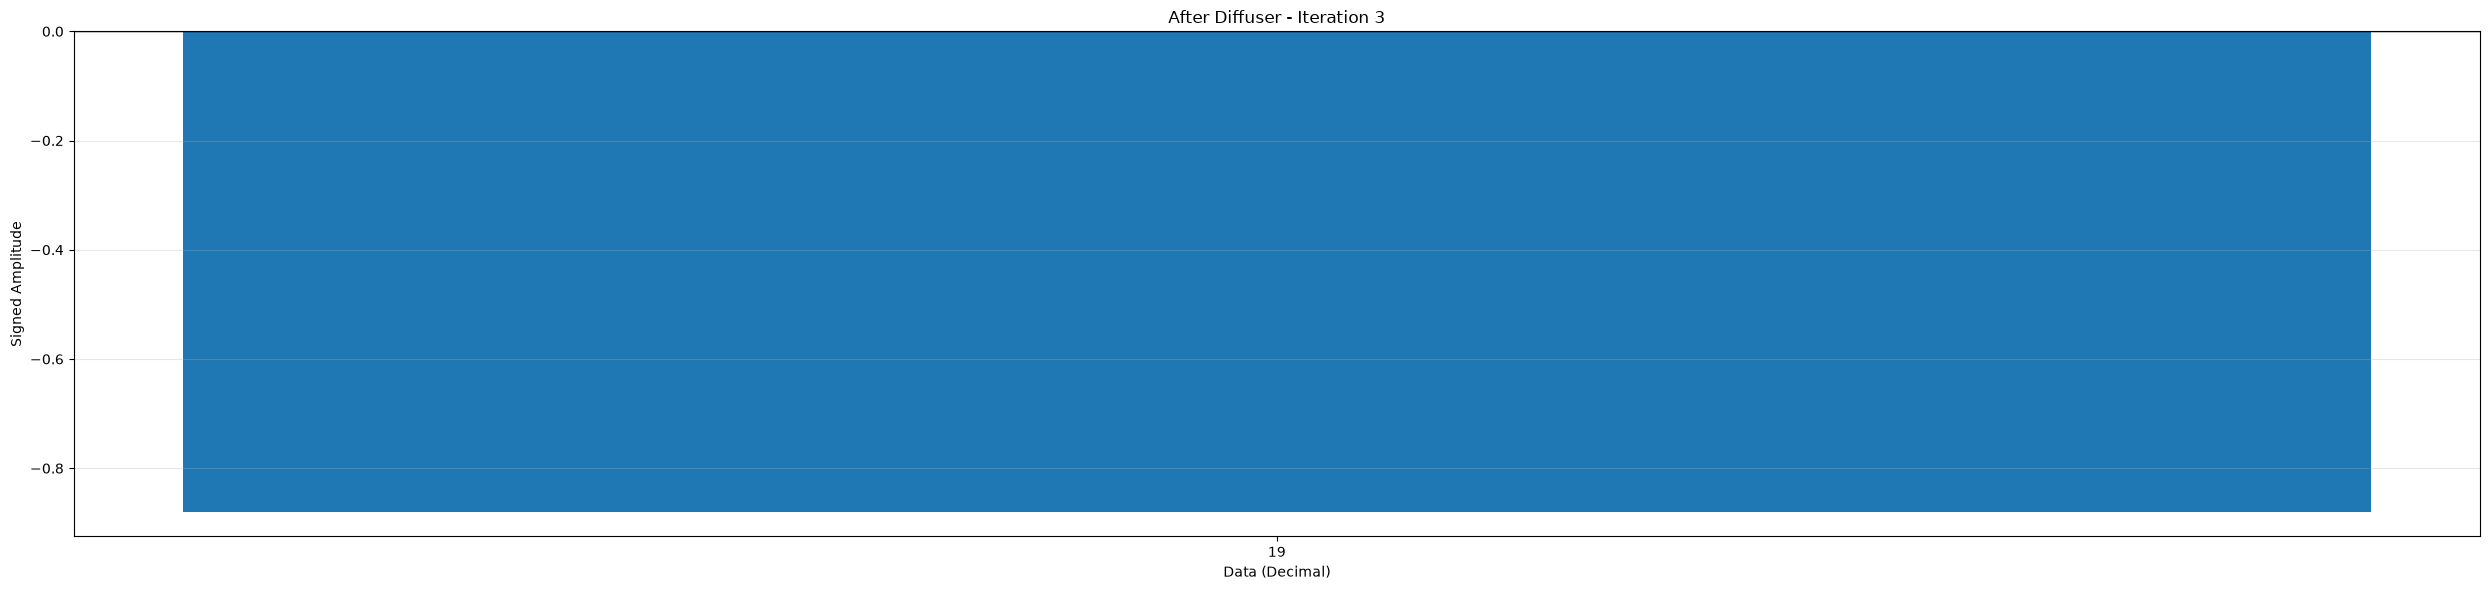


> Final quantum state:


<IPython.core.display.Latex object>


> Search completed.
Target element =  19
Most probable measured value =  19
Probability of target =  0.9999999999999205


In [10]:
GL = GroverLong()
result = GL.run(dataset, target)

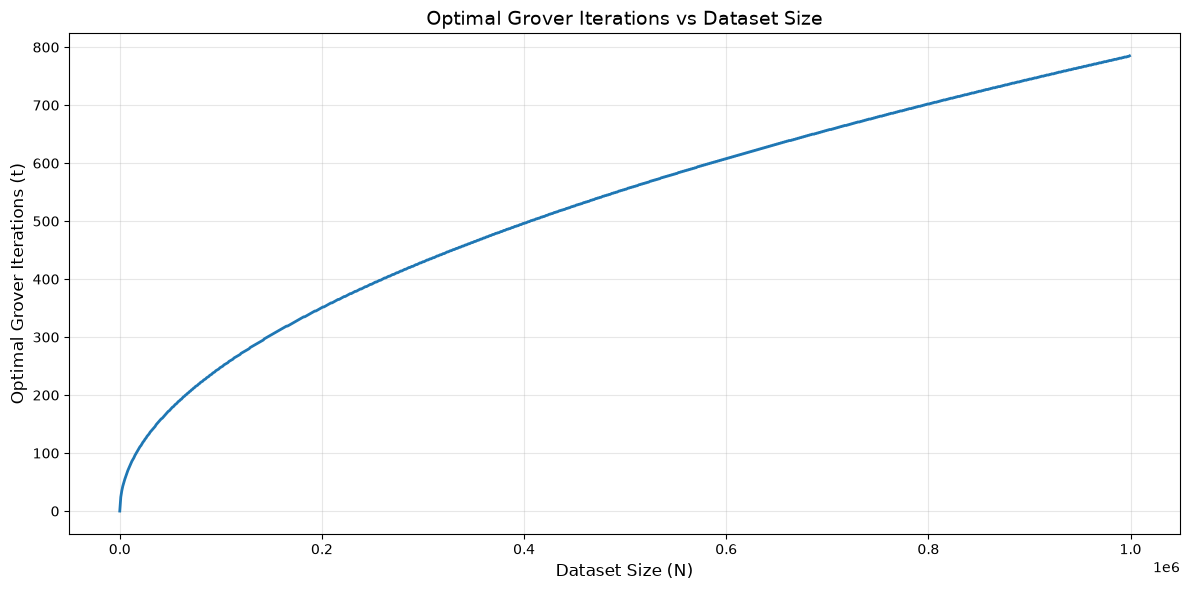

In [12]:
# Dataset sizes
N_values = range(1, 1000000, 1000)
M = 1

# Calculate optimal iterations for each N
t_values = [round(np.pi / (4 * np.arcsin(np.sqrt(M / N))) - 0.5)for N in N_values]

plt.figure(figsize=(12, 6))
plt.plot(N_values, t_values, linewidth=2)
plt.xlabel("Dataset Size (N)", fontsize=12)
plt.ylabel("Optimal Grover Iterations (t)", fontsize=12)
plt.title("Optimal Grover Iterations vs Dataset Size", fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()